# Un décideur typé (choix parmi options, probabilité lue) est-il aussi précis et aussi stable qu'un CamemBERT fine-tuné quand on change l'ordre, les étiquettes ou le texte annexe ?

> **En bref.** Le décideur typé ouvert est très sensible à l'ordre des options, alors que CamemBERT reste stable sous permutation. L'écart de précision dépend de l'ordre et d'une référence probablement sous-entraînée, donc il est à relativiser. taux de changement sous permutation : 0,534 [0,488 ; 0,576] pour Décideur typé (Qwen/Qwen3-1.7B), contre 0 [0 ; 0] pour CamemBERT-base fine-tuné (500 exemples de test, échelle complète).

| | |
|---|---|
| **Question** | Sur 77 intentions françaises proches, un décideur typé ouvert (Qwen3-1.7B, choix parmi 10 candidats) atteint au plus 5 points d'accuracy de moins que CamemBERT fine-tuné, mais change de décision sur plus de 5 % des exemples quand l'ordre des options est permuté, alors que CamemBERT a 0 % par construction. |
| **Référence** | CamemBERT-base fine-tuné — Classifieur d'intentions à 77 classes, tête de classification sur CamemBERT-base, entraîné sur le jeu d'entraînement complet. Déterministe, insensible à l'ordre des classes. |
| **Nouvelle approche** | Décideur typé ouvert sur candidats — Proxy ouvert d'un modèle de décision typé : un LLM instruct reçoit le texte et 10 options étiquetées, et rend la distribution de probabilité sur le symbole de l'option (réponse typée, sans texte généré). Les 10 candidats viennent du top-10 de CamemBERT. On mesure précision, calibration et changement de décision sous permutation. |
| **Données publiques** | [`DeepPavlov/banking77_fr`](https://huggingface.co/datasets/DeepPavlov/banking77_fr) (default) |
| **Métrique principale** | taux de changement sous permutation (à minimiser) |

**Sommaire** — 0. Mise en route · 1. La question · 2. Les données · 3. L'approche de référence · 4. La nouvelle approche · 5. Évaluation · 6. Analyse des résultats · 7. Bilan

**Trois façons d'exécuter ce notebook** (cellule de paramètres, section 0) :

| Réglage | À quoi ça sert |
|---|---|
| `PHASE = "public"`, `SCALE = "reduced"` | vérifier que tout fonctionne : quelques minutes sur CPU, sur un échantillon |
| `PHASE = "public"`, `SCALE = "full"` | reproduire les résultats publiés, sur tout le jeu public |
| `PHASE = "private"` | rejouer le même protocole sur vos données, dans votre environnement (voir le README) |

Les sorties affichées sont celles de l'échelle complète (`SCALE = "full"`).

## 0. Mise en route

Trois réglages suffisent : la **phase** (quelles données), l'**échelle** (combien de données et quels modèles) et la **graine** (mêmes tirages, mêmes résultats). Le même code sert aux deux phases : seule la source des données change.

- `PHASE = "public"` charge le jeu public ; `PHASE = "private"` lit vos données d'après `PRIVATE_CONFIG` (cellule suivante) et appelle vos services internes. En phase `private`, aucune donnée brute n'est affichée.
- `SCALE = "reduced"` prend un petit échantillon et, si besoin, des modèles plus petits de la même famille : c'est un test de la mécanique, ses chiffres ne valent pas résultat. `SCALE = "full"` utilise tout le jeu.
- Les fonctions communes (chargement des données internes, appels de services, intervalles de confiance, figures, enregistrement des résultats) sont dans `helpers.py`, à côté du notebook.

Fonctions de `helpers.py` utilisées ici :

| Fonction | Rôle |
|---|---|
| `set_seed` | Graine unique pour random, numpy et torch (s'ils sont présents) : résultats reproductibles. |
| `device` | Matériel de calcul disponible : « cuda » (GPU NVIDIA), « mps » (GPU Apple) ou « cpu ». |
| `sample_size` | Nombre d'exemples à utiliser : `reduced` à l'échelle réduite, `full` (None = tout le jeu) à l'échelle complète. |
| `by_scale` | Valeur qui dépend de l'échelle : modèle substitut, nombre d'époques, de pas ou d'exemples. |
| `model_path` | Chemin à passer à `from_pretrained`, dans les deux phases : l'identifiant Hugging Face, ou son dossier local sous LOCAL_MODELS_DIR (org--nom ou org/nom), seul accessible dans un environnement sans Internet. |
| `llm_chat` | Appel chat/completions. Avec `schema` (JSON Schema), rend l'objet décodé (None si la sortie est illisible) : sortie structurée si le service la prend en charge (mode strict si le schéma s'y prête), sinon consigne dans le prompt et décodage tolérant. |
| `load_private_data` | Jeu de la phase « private » : DataFrame aux colonnes attendues, lu dans PRIVATE_CONFIG['data'] (ou PRIVATE_DATA), fichier ou dossier (csv, tsv, parquet, jsonl, json, xlsx). |
| `preview` | Premières lignes en phase « public » ; en phase « private », seulement la structure (sauf SHOW_EXAMPLES=1). |
| `timer` | Mesure une durée en millisecondes : `with timer(liste): ...` ajoute la durée à `liste`. |
| `latency_stats` | Médiane (p50) et 95e centile (p95) d'une liste de durées en millisecondes. |
| `bootstrap_ci` | Valeur de `metric(y_true, y_pred)` et son intervalle de confiance à 95 % par bootstrap : (valeur, bas, haut). |
| `save_results` | Valide puis écrit results_<phase>.json dans le dossier des résultats. Structure attendue : |
| `results_table` | Tableau comparatif : une ligne par approche, chaque métrique avec son intervalle de confiance. |
| `save_figure` | Enregistre la figure (figures/<name>.png), l'affiche avec sa légende et la ferme ; ne renvoie rien. |
| `plot_comparison` | Figure de synthèse : une barre par approche et par métrique, avec l'intervalle de confiance à 95 % quand il existe. Par défaut, la métrique principale puis jusqu'à trois autres métriques. Une métrique sans objet pour une approche (None) n'a pas de barre pour elle. |

In [1]:
PHASE = "public"        # "public" : jeu public ; "private" : vos données, dans votre environnement
SCALE = "reduced"       # "reduced" : échantillon, quelques minutes sur CPU ; "full" : tout le jeu
SEED = 42               # graine : mêmes tirages, mêmes résultats
OUTPUT_DIR = "outputs"  # résultats (results_<phase>.json) et figures

### Configuration pour vos données

À modifier seulement pour `PHASE = "private"`. Chaque entrée est expliquée en commentaire ; les valeurs par défaut viennent des variables d'environnement décrites dans `private.env.example`. Au lancement, une liste de contrôle vérifie le jeu, les colonnes, les modèles et les services, et s'arrête sur ce qui manque avant tout calcul.

In [3]:
# Configuration pour vos données (PHASE = "private") : seule cellule à adapter.
# Les valeurs par défaut viennent de l'environnement (modèle : private.env.example).
# Aucune clé ici : elle vient de <SERVICE>_API_KEY, d'un fichier de secret monté (<SERVICE>_API_KEY_FILE) ou d'une saisie masquée.
import os

PRIVATE_CONFIG = {
    # Jeu de données : un fichier (csv, tsv, parquet, jsonl, json, xlsx) ou un dossier de fichiers de même structure.
    "data": os.environ.get("PRIVATE_DATA", ""),
    # Colonne attendue par le notebook -> nom de la colonne dans votre jeu (ne modifier que la partie droite).
    "columns": {'text': 'text', 'reason': 'reason', 'sub_reason': 'sub_reason', 'sub_reason_description': 'sub_reason_description', 'received_at': 'received_at'},
    # Colonnes qui contiennent des chemins de fichiers (relatifs au fichier de données qui les cite, ou absolus).
    "path_columns": [],
    "max_rows": None,                         # plafond facultatif (échantillon aléatoire reproductible)
    "csv": {"sep": None, "encoding": None},   # None : séparateur et encodage devinés (« ; », Windows-1252…)
    # Poids des modèles copiés localement (dossiers org--nom/, script download_models.py), pour travailler sans Internet.
    "models_dir": os.environ.get("LOCAL_MODELS_DIR", ""),
    "models": {'reduced': ['Qwen/Qwen3-0.6B', 'almanach/camembert-base'], 'full': ['Qwen/Qwen3-1.7B', 'almanach/camembert-base']},
    # Autorité de certification d'entreprise (fichier PEM) pour les appels HTTPS internes ; vide sinon.
    "ca_bundle": os.environ.get("SSL_CERT_FILE", ""),
    "llmaas": {"base_url": os.environ.get("LLMAAS_BASE_URL", ""), "model": os.environ.get("LLMAAS_MODEL", ""),
               "api_key_file": os.environ.get("LLMAAS_API_KEY_FILE", ""),
               "headers": {}},  # en-têtes exigés par votre passerelle, s'il y en a
}

### Dépendances et initialisation

Les versions exactes utilisées pour les résultats publiés sont dans `requirements.txt`. Les paquets propres à cette expérience s'installent depuis le notebook avec `INSTALL_DEPENDENCIES=1`.

In [4]:
# Paquets propres à cette expérience (en plus de requirements.txt).
EXTRA_PACKAGES = []
import os, subprocess, sys
if EXTRA_PACKAGES and os.environ.get("INSTALL_DEPENDENCIES") == "1":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *EXTRA_PACKAGES])

In [5]:
from helpers import *  # fonctions communes (voir le tableau ci-dessus)

configure(phase=PHASE, scale=SCALE, seed=SEED, output_dir=OUTPUT_DIR)
apply_private_config(PRIVATE_CONFIG)  # phase private : liste de contrôle, arrêt si quelque chose manque
prepare_environment()                 # télémétrie coupée ; hors ligne si les modèles sont locaux
use_plot_style()
show_configuration()

PHASE=public  SCALE=full  SEED=42  device=cuda  python=3.13.16
service LLM (convention OpenAI)               LLMAAS_BASE_URL=—  LLMAAS_MODEL=—  clé absente
service de transcription (convention OpenAI)  STTAAS_BASE_URL=—  STTAAS_MODEL=—  clé absente
données internes : —  modèles locaux : —


## 1. La question

Un **modèle de décision typé** ne rédige pas de réponse : il rend un **choix parmi des options**, avec une probabilité. Un audit récent (préprint arXiv 2611.06384, 702 000 jugements) montre que ces modèles **changent d'avis quand on déplace les options** ou qu'on ajoute un texte annexe, alors que le contenu à juger ne change pas.

On transpose ici la question à une tâche de services financiers : ranger une demande client française dans l'une de **77 intentions proches** (carte de paiement, virement, frais…). Un décideur typé est-il **aussi précis** qu'un classifieur fine-tuné, et **aussi stable** quand seule la présentation change ?

### Les deux approches

- **Référence : CamemBERT-base fine-tuné.** Une tête de classification sur les 77 classes. Il ne voit jamais la liste d'options ; on **mesure** quand même sa stabilité, en relançant sa chaîne de décision sous chaque présentation.
- **Nouvelle approche : un décideur typé ouvert (Qwen3).** C'est un peu comme un QCM : le modèle lit la demande et dix réponses étiquetées A à J, puis coche une case. On ne le laisse pas rédiger : on lit directement **la probabilité qu'il donne à chaque lettre**.

### Le principe, étape par étape

1. CamemBERT propose ses 10 intentions les plus probables : ce sont les **candidats**.
2. On présente la demande et les candidats au décideur sous plusieurs **présentations** : ordre du rang, ordre inversé, ordre aléatoire (à l'échelle complète, on ajoute les étiquettes 0–9 et une note annexe neutre).
3. Le modèle fait une seule passe avant, puis on applique un softmax sur les logits des 10 symboles : on obtient une **distribution typée**.
4. On compare le choix d'une présentation à l'autre : c'est le **taux de changement sous permutation** (`permutation_flip_rate`), la métrique principale, mesurée pour les deux approches.

### Ce que la comparaison permet de décider

Suppose que le décideur perde peu de précision, mais change d'avis sur une part notable des demandes dès qu'on réordonne les options. Il ne peut alors pas servir à router des demandes sans garde-fou, et le classifieur fine-tuné reste la référence. S'il est à la fois précis et stable, il devient une option crédible, utile quand les intentions évoluent souvent, puisqu'il n'a pas besoin d'être réentraîné.

## 2. Les données

### Réglages et outils de découpage

On regroupe ici les tailles d'échantillon et deux fonctions qui servent dans les deux phases :
- `sample_rows` tire des lignes au hasard avec la graine de l'expérience, donc toujours les mêmes ;
- `split_train_validation` met de côté 10 % de l'entraînement pour **choisir la meilleure époque**, en gardant les mêmes proportions de classes (**stratification**) quand les effectifs le permettent.

In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datasets import load_dataset
from IPython.display import display
from sklearn.model_selection import train_test_split

PUBLIC_DATASET = "DeepPavlov/banking77_fr"  # requêtes clients en français, 77 intentions
LABEL_NAMES_DATASET = "mteb/banking77"  # version anglaise : fournit le nom de chaque intention
TRAIN_POOL_SIZE = sample_size(reduced=800, full=None)  # textes pour CamemBERT (None = tout le train)
TEST_SIZE = sample_size(reduced=150, full=500)  # sous-échantillon de test fixe, commun aux deux approches
VALIDATION_SHARE = 0.10  # part de l'entraînement réservée au choix de l'époque


def sample_rows(df: pd.DataFrame, n: int | None) -> pd.DataFrame:
    """Tire `n` lignes au hasard avec la graine de l'expérience (tout le tableau, mélangé, si `n` est None)."""
    if n is None or n >= len(df):
        return df.sample(frac=1.0, random_state=SEED).reset_index(drop=True)
    return df.sample(n=n, random_state=SEED).reset_index(drop=True)


def split_train_validation(df: pd.DataFrame, share: float) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Sépare entraînement et validation, stratifié par classe quand c'est possible."""
    n_validation = max(1, int(round(len(df) * share)))
    counts = df["label"].value_counts()
    can_stratify = counts.min() >= 2 and n_validation >= df["label"].nunique()
    train_part, validation_part = train_test_split(
        df, test_size=n_validation, random_state=SEED,
        stratify=df["label"] if can_stratify else None,
    )
    return train_part.reset_index(drop=True), validation_part.reset_index(drop=True)

### Chargement du jeu public

`DeepPavlov/banking77_fr` contient le texte (`utterance`) et un **entier** d'étiquette. Les noms d'intention (`label_text`) viennent de la version anglaise `mteb/banking77`, qui suit la même numérotation. Ce sont eux qui servent d'**options** pour le décideur, avec les tirets bas remplacés par des espaces.

À la fin de la section, les variables `train_df`, `validation_df`, `test_df`, `classes` et `option_text` existent. La section des données internes définit exactement les mêmes.

In [7]:
def load_public_frames() -> tuple[pd.DataFrame, pd.DataFrame, dict[int, str]]:
    """Charge le jeu français et rattache à chaque entier d'étiquette le nom anglais de l'intention."""
    raw = load_dataset(PUBLIC_DATASET, "default")
    names = load_dataset(LABEL_NAMES_DATASET, split="test").to_pandas()
    id_to_name = {int(k): str(v) for k, v in zip(names["label"], names["label_text"])}
    assert len(id_to_name) == 77, f"{len(id_to_name)} noms d'intentions trouvés au lieu de 77"
    frames = []
    for split in ("train", "test"):
        df = raw[split].to_pandas()
        assert {"utterance", "label"} <= set(df.columns), list(df.columns)
        frame = pd.DataFrame({"text": df["utterance"].astype(str).str.strip(),
                              "label": pd.to_numeric(df["label"]).astype(int).map(id_to_name)})
        assert frame["label"].notna().all(), "étiquette sans nom d'intention"
        frames.append(frame[frame["text"] != ""].reset_index(drop=True))
    return frames[0], frames[1], id_to_name


if PHASE == "public":
    public_train, public_test, id_to_name = load_public_frames()
    train_pool = sample_rows(public_train, TRAIN_POOL_SIZE)
    test_df = sample_rows(public_test, TEST_SIZE)
    train_df, validation_df = split_train_validation(train_pool, VALIDATION_SHARE)
    classes = sorted(id_to_name.values())
    option_text = {name: name.replace("_", " ") for name in classes}  # libellé montré au décideur
    label_parent = None  # pas de hiérarchie motif / sous-motif dans le jeu public
    dataset_info = {"name": PUBLIC_DATASET, "config": "default", "split": "test"}
    # Contrôle visuel de la correspondance entier -> nom sur un exemple réel
    sample = public_train[public_train["label"] == id_to_name[0]].iloc[0]
    print(f"Étiquette 0 = « {id_to_name[0]} » ; exemple : « {sample['text']} »")

README.md:   0%|          | 0.00/415 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  313kB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 98.5kB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/10003 [00:00<?, ? examples/s]

... (5 outputs left out)

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/9993 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3076 [00:00<?, ? examples/s]

Étiquette 0 = « activate_my_card » ; exemple : « S'il vous plaît, aidez-moi avec ma carte.  Il ne s'activera pas. »


### Contrôles : effectifs et longueurs

Avant d'entraîner quoi que ce soit, on vérifie la taille de chaque partie, le nombre de classes présentes, l'effectif minimal et maximal par classe, et la longueur des textes en mots. Une classe absente de l'entraînement ne pourra jamais être prédite par CamemBERT : c'est cette vérification qui permet de le repérer.

In [8]:
def describe_splits(splits: dict[str, pd.DataFrame]) -> pd.DataFrame:
    """Effectifs, nombre de classes et longueurs (en mots) de chaque partie du jeu."""
    rows = []
    for name, df in splits.items():
        words = df["text"].str.split().str.len()
        counts = df["label"].value_counts()
        rows.append({"partie": name, "textes": len(df), "classes": df["label"].nunique(),
                     "min par classe": int(counts.min()), "max par classe": int(counts.max()),
                     "mots (médiane)": float(words.median()), "mots (max)": int(words.max())})
    return pd.DataFrame(rows)


if PHASE == "public":
    display(describe_splits({"entraînement": train_df, "validation": validation_df, "test": test_df}))

,partie,textes,classes,min par classe,max par classe,mots (médiane),mots (max)
0,entraînement,9003,77,31,168,10.0,84
1,validation,1000,77,4,19,10.0,60
2,test,500,77,3,14,10.0,72


### Figure : à quoi ressemblent les données

À gauche, l'effectif de chaque classe à l'entraînement. Plus il y a de classes peu représentées, plus la tâche est dure pour le classifieur fine-tuné. À droite, la longueur des textes : des demandes courtes laissent peu d'indices pour départager des intentions proches.

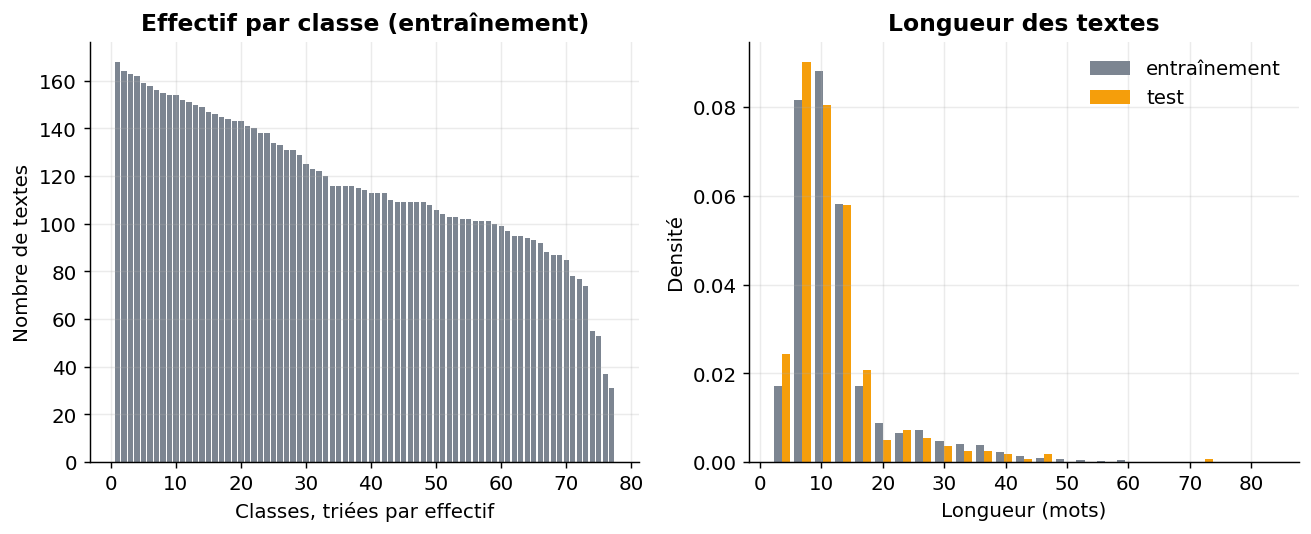

*Figure — À gauche, le nombre de textes d'entraînement par classe, trié par ordre décroissant (une barre = une intention). À droite, la distribution de la longueur des textes en mots, à l'entraînement et au test : deux courbes proches veulent dire que le test ressemble à l'entraînement.*

In [9]:
def plot_data_overview(train_part: pd.DataFrame, test_part: pd.DataFrame, name: str) -> None:
    """Deux panneaux : effectif de chaque classe à l'entraînement, et longueur des textes en mots."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    counts = train_part["label"].value_counts()
    axes[0].bar(np.arange(1, len(counts) + 1), counts.to_numpy(), color=COLORS["reference"])
    axes[0].set(title="Effectif par classe (entraînement)", xlabel="Classes, triées par effectif",
                ylabel="Nombre de textes")
    lengths = [part["text"].str.split().str.len() for part in (train_part, test_part)]
    axes[1].hist(lengths, bins=25, density=True, label=["entraînement", "test"],
                 color=[COLORS["reference"], COLORS["accent"]])
    axes[1].set(title="Longueur des textes", xlabel="Longueur (mots)", ylabel="Densité")
    axes[1].legend()
    save_figure(fig, name, "À gauche, le nombre de textes d'entraînement par classe, trié par ordre "
                "décroissant (une barre = une intention). À droite, la distribution de la longueur des "
                "textes en mots, à l'entraînement et au test : deux courbes proches veulent dire que le "
                "test ressemble à l'entraînement.")


if PHASE == "public":
    plot_data_overview(train_df, test_df, "data_overview")

### Quelques exemples

`preview` affiche les premières lignes en phase publique. En phase données internes, il n'affiche que la structure.

In [10]:
if PHASE == "public":
    preview(test_df, n=5)

### Jeu factice de remplacement : la taxonomie

Pour tester le code sans aucune donnée réelle, on fabrique des demandes plausibles réparties en **motifs** (premier niveau) et **sous-motifs** (feuilles de l'arbre). Chaque sous-motif a un libellé en français, qui sera montré au décideur comme option. Tout est inventé.

In [11]:
PRIVATE_TEST_SHARE = 0.25  # part la plus récente des données réservée au test (découpage temporel)
FAKE_TAXONOMY = {  # sous-motif -> (motif, libellé, modèles de phrases) ; entièrement inventé
    "carte_bloquee": ("carte", "Carte de paiement bloquée ou refusée", [
        "Ma carte est refusée à chaque paiement depuis {day}.", "Ma carte a été bloquée après trois codes faux.",
        "Impossible de retirer de l'argent, ma carte ne passe plus."]),
    "carte_perdue": ("carte", "Carte perdue ou volée, mise en opposition", [
        "J'ai perdu ma carte {day}, pouvez-vous la bloquer ?", "On m'a volé ma carte dans le métro.",
        "Je ne retrouve plus ma carte de paiement, je veux faire opposition."]),
    "carte_livraison": ("carte", "Nouvelle carte non reçue", [
        "Je n'ai toujours pas reçu la carte demandée {day}.", "Quand vais-je recevoir ma carte de remplacement ?",
        "La nouvelle carte n'est pas arrivée dans ma boîte aux lettres."]),
    "virement_non_recu": ("virement", "Virement attendu non reçu", [
        "Le virement de {amount} euros envoyé {day} n'est pas arrivé.", "Mon salaire n'apparaît pas sur mon compte.",
        "Un proche m'a fait un virement mais je ne vois rien."]),
    "virement_annulation": ("virement", "Annuler ou modifier un virement", [
        "Je me suis trompé de bénéficiaire pour un virement de {amount} euros.",
        "Peut-on annuler le virement fait {day} ?", "J'ai saisi le mauvais montant, comment corriger le virement ?"]),
    "virement_plafond": ("virement", "Plafond de virement atteint", [
        "Je ne peux pas envoyer {amount} euros, le plafond est atteint.", "Comment augmenter ma limite de virement ?",
        "Mon virement est refusé pour dépassement de plafond."]),
    "frais_contestation": ("frais", "Contestation de frais prélevés", [
        "Des frais de {amount} euros ont été prélevés sans explication.",
        "Pourquoi ai-je payé des frais sur mon dernier retrait ?", "Je conteste les frais de tenue de compte."]),
    "frais_change": ("frais", "Frais ou taux de change à l'étranger", [
        "Le taux de change appliqué à mon paiement à l'étranger est faux.",
        "Combien coûte un paiement en dollars avec ma carte ?", "J'ai payé {amount} euros de frais de change."]),
    "compte_acces": ("compte", "Accès à l'espace client impossible", [
        "Je n'arrive plus à me connecter à mon espace client depuis {day}.", "Mon mot de passe ne fonctionne plus.",
        "L'application me déconnecte sans arrêt."]),
    "compte_cloture": ("compte", "Clôture du compte", [
        "Je veux fermer mon compte.", "Quelle est la procédure pour clôturer mon compte ?",
        "Merci de résilier mon compte à la fin du mois."]),
}

### Générateur de données factices et colonnes attendues

`PRIVATE_COLUMNS` reprend **exactement** les colonnes prévues pour les données internes. La cellule `PRIVATE_CONFIG`, plus haut, fait le lien avec les vrais noms de colonnes. `make_fake_data(n)` produit `n` demandes équilibrées entre sous-motifs, avec des formules d'ouverture et de politesse variées, des montants et des dates de réception étalées sur environ 14 mois (pour pouvoir faire un découpage temporel).

In [12]:
PRIVATE_COLUMNS = {
    "text": "Texte du message ou de la demande client, anonymisé",
    "reason": "Motif de premier niveau (étiquette de référence)",
    "sub_reason": "Sous-motif (étiquette de référence, feuille de l'arbre)",
    "sub_reason_description": "Libellé ou description courte du sous-motif, présentée comme option au décideur",
    "received_at": "Date de réception, pour le découpage temporel",
}
FAKE_DAYS = ["hier", "lundi dernier", "la semaine dernière", "il y a trois jours", "ce matin"]
FAKE_OPENERS = ["", "Bonjour, ", "Bonsoir, ", "Madame, Monsieur, "]
FAKE_CLOSERS = ["", " Merci d'avance.", " C'est urgent.", " Cordialement."]
N_FAKE = 600  # assez de lignes pour avoir au moins 100 exemples de test après le découpage temporel


def make_fake_data(n: int) -> pd.DataFrame:
    """Jeu factice plausible (aucune donnée réelle) : demande, motif, sous-motif, libellé, date de réception."""
    rng = np.random.default_rng(SEED)
    sub_reasons = list(FAKE_TAXONOMY)
    start = pd.Timestamp("2025-01-01")
    rows = []
    for i in range(n):
        sub_reason = sub_reasons[i % len(sub_reasons)]  # classes équilibrées
        reason, description, templates = FAKE_TAXONOMY[sub_reason]
        body = str(rng.choice(templates)).format(day=rng.choice(FAKE_DAYS), amount=int(rng.integers(20, 3000)))
        opener = str(rng.choice(FAKE_OPENERS))
        body = body[0].lower() + body[1:] if opener else body
        rows.append({"text": opener + body + str(rng.choice(FAKE_CLOSERS)), "reason": reason,
                     "sub_reason": sub_reason, "sub_reason_description": description,
                     "received_at": start + pd.Timedelta(minutes=int(rng.integers(0, 60 * 24 * 420)))})
    return pd.DataFrame(rows)

### Chargement, typage et découpage temporel

Le jeu, factice ou non, est **relu depuis un fichier**. On convertit donc chaque colonne explicitement (texte, date), on retire les lignes vides, puis on trie par date de réception. Le **test** est la période la plus récente (les 25 % derniers), comme en conditions réelles, où l'on prédit le futur à partir du passé. On ne suppose rien sur les classes : elles sont déduites des données, et le libellé de chaque sous-motif devient l'option présentée au décideur.

In [13]:
if PHASE == "private":
    private_raw = load_private_data(PRIVATE_COLUMNS, make_fake_data, n_fake=N_FAKE)
    missing = set(PRIVATE_COLUMNS) - set(private_raw.columns)
    assert not missing, f"colonnes manquantes : {sorted(missing)}"
    data = pd.DataFrame({
        "text": private_raw["text"].astype(str).str.strip(),
        "label": private_raw["sub_reason"].astype(str).str.strip(),
        "reason": private_raw["reason"].astype(str).str.strip(),
        "description": private_raw["sub_reason_description"].astype(str).str.strip(),
        "received_at": pd.to_datetime(private_raw["received_at"], errors="coerce"),
    })
    empty = data["text"].isin(["", "nan", "None"]) | data["label"].isin(["", "nan", "None"])
    data = data[~empty & data["received_at"].notna()]
    data = data.sort_values(["received_at", "text"]).reset_index(drop=True)  # ordre des lignes non supposé
    cut = int(len(data) * (1 - PRIVATE_TEST_SHARE))
    train_pool = sample_rows(data.iloc[:cut], TRAIN_POOL_SIZE)
    test_df = sample_rows(data.iloc[cut:], TEST_SIZE)
    train_df, validation_df = split_train_validation(train_pool, VALIDATION_SHARE)
    classes = sorted(data["label"].unique())
    option_text = data.groupby("label")["description"].agg(lambda s: s.mode().iloc[0]).to_dict()
    label_parent = data.groupby("label")["reason"].agg(lambda s: s.mode().iloc[0]).to_dict()
    dataset_info = {"name": "données internes", "config": "sub_reason", "split": "période la plus récente"}
    print(f"{len(data)} textes utilisables, {len(classes)} sous-motifs, "
          f"test à partir du {data['received_at'].iloc[cut]:%Y-%m-%d}")

### Mêmes contrôles et même figure qu'en phase publique

On n'affiche que des agrégats (effectifs, longueurs) et la structure du tableau, jamais de texte brut.

In [14]:
if PHASE == "private":
    display(describe_splits({"entraînement": train_df, "validation": validation_df, "test": test_df}))
    plot_data_overview(train_df, test_df, "data_overview")
    preview(test_df)

## 3. L'approche de référence

### Réglages de la référence : CamemBERT-base fine-tuné

On ajoute une **tête de classification**, c'est-à-dire une couche linéaire à une sortie par classe, sur l'encodeur français CamemBERT-base, puis on entraîne le tout. Réglages prévus : 3 époques, taux d'apprentissage $3\cdot10^{-5}$, lots de 32. À l'échelle réduite, il y a peu de textes et peu de pas : on prend des lots plus petits et un taux plus fort pour que la référence apprenne quand même quelque chose.

La **précision mixte** (calcul en 16 bits) n'est activée que sur GPU NVIDIA.

In [15]:
import copy
import gc
import math
import os
import time

import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer, get_linear_schedule_with_warmup

ENCODER_ID = "almanach/camembert-base"  # encodeur français de référence
EPOCHS = by_scale(reduced=2, full=3)  # 3 époques prévues ; 2 à l'échelle réduite
LEARNING_RATE = by_scale(reduced=1e-4, full=3e-5)  # taux plus fort quand il y a très peu de pas
BATCH_SIZE = by_scale(reduced=16, full=32)  # petits lots = plus de mises à jour sur peu de textes
PLANNED_MAX_LENGTH = 64  # plafond de tokens prévu, relevé si trop de textes seraient coupés
WEIGHT_DECAY = 0.01  # régularisation habituelle d'AdamW
WARMUP_SHARE = 0.10  # part des pas en montée progressive du taux
LATENCY_SAMPLE = 50  # exemples chronométrés un par un pour la latence
DEVICE = device()
USE_AMP = DEVICE == "cuda"  # précision mixte seulement sur GPU NVIDIA
AUTOCAST_DEVICE = "cuda" if USE_AMP else "cpu"

label_to_id = {label: index for index, label in enumerate(classes)}
set_seed(SEED)
encoder_tokenizer = AutoTokenizer.from_pretrained(model_path(ENCODER_ID))
print(f"Calcul sur {DEVICE} ; {len(classes)} classes ; tokeniseur {type(encoder_tokenizer).__name__}")

config.json:   0%|          | 0.00/508 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/811k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.40M [00:00<?, ?B/s]

Calcul sur cuda ; 77 classes ; tokeniseur CamembertTokenizer


### Les présentations, communes aux deux approches

Une **présentation** fixe l'ordre des 10 candidats et leurs **symboles** :
- `rank` suit l'ordre de CamemBERT, `reversed` l'inverse, `random` un mélange propre à chaque exemple (tiré avec la graine) ;
- `digits` remplace A–J par 0–9, et `neutral_note` ajoute une phrase sans rapport avec la demande.

Elles sont définies ici, car on les applique **aussi à la référence** : sa stabilité est mesurée, pas supposée.

In [16]:
ALL_PRESENTATIONS = ["rank", "reversed", "random", "digits", "neutral_note"]  # toutes testées une fois
ORDER_PRESENTATIONS = ["rank", "reversed", "random"]  # ne changent que l'ordre : base du flip rate
PRESENTATIONS = by_scale(reduced=ORDER_PRESENTATIONS, full=ALL_PRESENTATIONS)  # évaluées sur tout le test
LETTERS = list("ABCDEFGHIJ")  # symboles des options, présentation par défaut
DIGITS = list("0123456789")  # symboles de la présentation « digits »
NEUTRAL_NOTE = "Note : cette demande a été reçue par le canal habituel, pendant les heures d'ouverture."


def present_options(candidate_row: list[str], presentation: str, example_index: int):
    """Ordre d'affichage des candidats et symboles associés, pour une présentation donnée."""
    order = list(candidate_row)
    if presentation == "reversed":
        order = order[::-1]
    elif presentation == "random":
        rng = np.random.default_rng([SEED, int(example_index)])  # mélange reproductible, propre à l'exemple
        order = [order[j] for j in rng.permutation(len(order))]
    symbols = (DIGITS if presentation == "digits" else LETTERS)[:len(order)]
    return order, symbols


print(f"Présentations évaluées : {PRESENTATIONS}")

Présentations évaluées : ['rank', 'reversed', 'random', 'digits', 'neutral_note']


### Combien de tokens ? On choisit un plafond qui ne coupe pas les textes

Un texte plus long que le plafond est **tronqué**, et la fin coupée peut contenir l'indice décisif. On mesure donc la longueur en tokens de tous les textes. On garde le plafond prévu (64) s'il laisse **au moins 95 % des textes entiers dans chaque classe** ; sinon, on le relève.

In [17]:
def choose_max_length(texts: list[str], labels: list[str], planned: int, min_kept: float = 0.95):
    """Plus petit plafond (à partir du plafond prévu) qui laisse `min_kept` des textes entiers dans chaque classe."""
    lengths = pd.Series([len(ids) for ids in encoder_tokenizer(list(texts))["input_ids"]])
    frame = pd.DataFrame({"label": list(labels), "tokens": lengths})
    for cap in [planned, 96, 128, 192, 256, 512]:
        worst = float((frame["tokens"] > cap).groupby(frame["label"]).mean().max())
        if worst <= 1 - min_kept:
            break
    summary = pd.DataFrame([{
        "plafond retenu (tokens)": cap, "tokens (médiane)": float(lengths.median()),
        "tokens (max)": int(lengths.max()), "part coupée, toutes classes": float((lengths > cap).mean()),
        "part coupée, pire classe": worst}])
    return cap, summary


all_texts = pd.concat([train_df, validation_df, test_df], ignore_index=True)
MAX_LENGTH, length_summary = choose_max_length(all_texts["text"], all_texts["label"], PLANNED_MAX_LENGTH)
display(length_summary.round(3))

,plafond retenu (tokens),tokens (médiane),tokens (max),"part coupée, toutes classes","part coupée, pire classe"
0,96,16.0,113,0.0,0.017


### Prédire des probabilités

Le texte est découpé en tokens, puis le modèle sort un **logit** (un score brut) par classe, et le **softmax** transforme ces scores en probabilités qui somment à 1. On travaille par lots, et la mémoire du GPU n'est pas sollicitée par le calcul des gradients (`torch.no_grad`).

In [18]:
def encode_batch(texts: list[str]) -> dict:
    """Tokenise un lot de textes, complété à la longueur du plus long et coupé au plafond retenu."""
    return encoder_tokenizer(list(texts), truncation=True, max_length=MAX_LENGTH, padding=True,
                             return_tensors="pt")


def predict_probabilities(model, texts: list[str], batch_size: int = 64) -> np.ndarray:
    """Probabilités de chaque classe (tableau n_textes × n_classes)."""
    model.eval()
    outputs = []
    with torch.no_grad():
        for start in range(0, len(texts), batch_size):
            batch = encode_batch(texts[start:start + batch_size]).to(DEVICE)
            with torch.autocast(device_type=AUTOCAST_DEVICE, enabled=USE_AMP):
                logits = model(**batch).logits
            outputs.append(torch.softmax(logits.float(), dim=-1).cpu().numpy())
    return np.concatenate(outputs)

### Boucle d'entraînement

C'est un fine-tuning classique :
- **AdamW**, avec une montée progressive du taux (warmup) puis une décroissance linéaire ;
- **écrêtage des gradients** à 1, pour éviter les pas trop brusques ;
- après chaque époque, on mesure l'accuracy de validation et on **garde les poids de la meilleure époque**.

L'ordre des lots est tiré avec la graine de l'expérience.

In [19]:
def train_encoder(train_part: pd.DataFrame, validation_part: pd.DataFrame):
    """Fine-tune CamemBERT ; rend le modèle à la meilleure époque de validation et l'historique."""
    set_seed(SEED)
    model = AutoModelForSequenceClassification.from_pretrained(
        model_path(ENCODER_ID), num_labels=len(classes)).to(DEVICE)
    texts = train_part["text"].tolist()
    labels = torch.tensor(train_part["label"].map(label_to_id).to_numpy())
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    total_steps = EPOCHS * math.ceil(len(texts) / BATCH_SIZE)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_SHARE * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    generator = torch.Generator().manual_seed(SEED)
    best_accuracy, best_state, history = -1.0, None, []
    for epoch in range(1, EPOCHS + 1):
        model.train()
        started, order = time.perf_counter(), torch.randperm(len(texts), generator=generator).tolist()
        for start in range(0, len(order), BATCH_SIZE):
            index = order[start:start + BATCH_SIZE]
            batch = encode_batch([texts[i] for i in index]).to(DEVICE)
            with torch.autocast(device_type=AUTOCAST_DEVICE, enabled=USE_AMP):
                loss = model(**batch, labels=labels[index].to(DEVICE)).loss
            optimizer.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
        probabilities = predict_probabilities(model, validation_part["text"].tolist())
        predicted = np.array(classes)[probabilities.argmax(axis=1)]
        accuracy = float(np.mean(predicted == validation_part["label"].to_numpy()))
        history.append({"époque": epoch, "perte (dernier lot)": float(loss), "accuracy validation": accuracy,
                        "durée (s)": time.perf_counter() - started})
        if accuracy > best_accuracy:  # on garde une copie des meilleurs poids, sur CPU
            best_accuracy = accuracy
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model, pd.DataFrame(history)

### Entraînement, prédictions de test et candidats du décideur

On entraîne, puis on prédit sur le test. Le **top-10** de CamemBERT, c'est-à-dire ses 10 classes les plus probables, sert de liste de **candidats** au décideur. Le **rappel du top-10** (la part des exemples dont la bonne classe est dans cette liste) est donc le **plafond** du décideur : il ne peut pas choisir une classe qu'on ne lui montre pas.

In [20]:
encoder, training_history = train_encoder(train_df, validation_df)
display(training_history.round(3))

test_texts = test_df["text"].tolist()
y_true = test_df["label"].to_numpy()
reference_probabilities = predict_probabilities(encoder, test_texts)
N_CANDIDATES = min(10, len(classes))  # 10 options au plus, comme prévu
candidate_ids = np.argsort(-reference_probabilities, axis=1)[:, :N_CANDIDATES]
candidates = [[classes[j] for j in row] for row in candidate_ids]
reference_pred = np.array([row[0] for row in candidates])
in_top_candidates = np.array([label in row for label, row in zip(y_true, candidates)])
print(f"CamemBERT : accuracy test {np.mean(reference_pred == y_true):.3f} ; "
      f"rappel du top-{N_CANDIDATES} {in_top_candidates.mean():.3f}")

model.safetensors: reconstructing file:   0%|          |  0.00B /  445MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] CamembertForSequenceClassification LOAD REPORT from: almanach/camembert-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


/tmp/ipykernel_617/3509521206.py:32: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  history.append({"époque": epoch, "perte (dernier lot)": float(loss), "accuracy validation": accuracy,


,époque,perte (dernier lot),accuracy validation,durée (s)
0,1,3.528,0.553,35.248
1,2,3.006,0.670,34.743
2,3,2.646,0.702,36.039


CamemBERT : accuracy test 0.676 ; rappel du top-10 0.954


### La référence sous chaque présentation : une mesure, pas une hypothèse

Pour chaque présentation, on **relance réellement** la chaîne de décision de CamemBERT :
- les exemples passent dans un ordre propre à la présentation (lots et remplissage différents, ce qui fait apparaître un éventuel bruit numérique) ;
- sous `neutral_note`, la note neutre est ajoutée au texte ;
- le choix est le candidat **affiché** le plus probable, la liste étant lue dans l'ordre d'affichage.

On mesure ensuite la latence, sur 50 textes pris un par un, puis on libère la mémoire.

In [21]:
def reference_input(text: str, presentation: str) -> str:
    """Texte vu par CamemBERT : la demande, suivie de la note neutre sous la présentation `neutral_note`."""
    return f"{text} {NEUTRAL_NOTE}" if presentation == "neutral_note" else text


def run_reference_presentations(model, presentations: list[str]) -> pd.DataFrame:
    """Choix de CamemBERT sous chaque présentation : nouvelle inférence, puis meilleur candidat affiché."""
    rows = []
    for p_index, presentation in enumerate(presentations):
        visit = np.random.default_rng([SEED, p_index]).permutation(len(test_texts))  # lots propres
        probabilities = np.empty_like(reference_probabilities)
        probabilities[visit] = predict_probabilities(
            model, [reference_input(test_texts[i], presentation) for i in visit])
        for i in range(len(test_texts)):
            order, _ = present_options(candidates[i], presentation, i)
            scores = probabilities[i, [label_to_id[c] for c in order]]
            rows.append({"example": i, "presentation": presentation, "choice": order[int(np.argmax(scores))]})
    return pd.DataFrame(rows)


reference_records = run_reference_presentations(encoder, PRESENTATIONS)
reference_latencies: list[float] = []
for text in test_texts[:LATENCY_SAMPLE]:
    with timer(reference_latencies):
        predict_probabilities(encoder, [text])
print(f"{len(reference_records)} décisions de référence ; latence médiane {np.median(reference_latencies):.1f} ms")
del encoder
gc.collect()
if DEVICE == "cuda":
    torch.cuda.empty_cache()

2500 décisions de référence ; latence médiane 12.6 ms


## 4. La nouvelle approche

### Nouvelle approche : un décideur typé ouvert

Ce qu'on reprend de la source (arXiv 2611.06384, section « comment ça marche », étapes 3 et 5) :
- le modèle rend une **réponse typée** : une distribution de probabilité sur les options, sans texte généré ;
- on **change une seule caractéristique de présentation à la fois** (ordre, étiquettes, texte annexe) sans toucher au contenu ;
- on compare le **choix**, sa **probabilité**, et la variation sur des **appels répétés à l'identique**.

Ce qui diffère de la source :
- les services propriétaires (Jev, Clef Flash, Perplexity Decider) ne sont pas testés : un LLM ouvert (Qwen3) en joue le rôle ;
- la tâche est une classification à classes nombreuses en français, pas un choix entre deux textes ;
- les options sont pré-filtrées par CamemBERT ;
- le calcul se fait en `float16` sur GPU (plutôt que `bfloat16`, mal pris en charge par le T4) et en `float32` sur CPU.

Les constantes ci-dessous fixent le modèle de chaque échelle et le **budget de temps** de la boucle d'inférence.

In [22]:
DECIDER_ID = by_scale(reduced="Qwen/Qwen3-0.6B", full="Qwen/Qwen3-1.7B")  # substitut léger à l'échelle réduite
INVALID = "__invalide__"  # choix illisible : compté comme une erreur
TIME_BUDGET_S = by_scale(reduced=450, full=1500)  # arrêt propre de la boucle au-delà de ce budget
MIN_EVALUATED = 100  # en deçà, l'évaluation n'est pas concluante
PROGRESS_EVERY = by_scale(reduced=25, full=50)  # fréquence du relevé de progression
N_CONTROL = sample_size(reduced=20, full=50)  # exemples du contrôle positif
DECIDER_DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32
print(f"Décideur : {DECIDER_ID} ; présentations évaluées : {PRESENTATIONS}")

Décideur : Qwen/Qwen3-1.7B ; présentations évaluées : ['rank', 'reversed', 'random', 'digits', 'neutral_note']


### Écrire la consigne

`build_messages` assemble le message de choix à partir de l'ordre et des symboles fixés par `present_options` (définie avec la référence). Le texte de la demande et les libellés ne changent jamais : seule la présentation varie (ordre, symboles, note neutre éventuelle).

In [23]:
def build_messages(text: str, order: list[str], symbols: list[str], presentation: str) -> list[dict]:
    """Message de choix : la demande, éventuellement une note neutre, puis les options étiquetées."""
    options = "\n".join(f"{symbol}. {option_text[label]}" for symbol, label in zip(symbols, order))
    note = NEUTRAL_NOTE + "\n" if presentation == "neutral_note" else ""
    kind = "un seul chiffre" if symbols[0].isdigit() else "une seule lettre"
    prompt = (f"Demande d'un client : « {text} »\n{note}"
              f"Quelle intention correspond le mieux à cette demande ?\n{options}\n"
              f"Réponds par {kind} ({symbols[0]}-{symbols[-1]}), sans autre texte.")
    return [{"role": "user", "content": prompt}]

### Deux outils du décideur local : tokens des symboles et prompt final

- `single_token_id` cherche l'identifiant du token de chaque symbole (A–J, 0–9). Si un symbole était découpé en plusieurs tokens, sa probabilité ne se lirait pas en une seule passe : on refuse donc ce cas par un `assert`.
- `render_chat_prompt` applique le *chat template* de Qwen3 **sans mode réflexion** (`enable_thinking=False`). On vérifie que le prompt se termine par la balise de réflexion vide : le prochain token attendu est alors directement le symbole choisi.

In [24]:
def single_token_id(tokenizer, symbol: str) -> int:
    """Identifiant du token d'un symbole ; refuse un symbole découpé en plusieurs tokens."""
    ids = tokenizer.encode(symbol, add_special_tokens=False)
    assert len(ids) == 1, f"le symbole {symbol!r} fait {len(ids)} tokens"
    return ids[0]


def render_chat_prompt(tokenizer, messages: list[dict]) -> str:
    """Prompt final, sans mode réflexion : le prochain token attendu est le symbole choisi."""
    rendered = tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True, enable_thinking=False)
    assert rendered.rstrip().endswith("</think>"), "mode réflexion non désactivé"
    return rendered

### Le décideur local : lire la probabilité des symboles

On fait **une seule passe avant**. On ne garde que les logits du dernier token (`logits_to_keep=1`, ce qui épargne de la mémoire et du calcul), et sur ces logits ceux des 10 symboles :

$$p(\text{option}_k) = \frac{e^{z_k}}{\sum_{j=1}^{10} e^{z_j}}$$

Le choix est l'option la plus probable. On relève aussi la **masse sur les symboles**, c'est-à-dire la part de probabilité que le modèle met sur les lettres attendues plutôt que sur d'autres tokens : c'est un indicateur de bonne compréhension du format.

In [25]:
class LocalDecider:
    """Décideur typé local : une passe avant, softmax sur les logits des symboles des options."""

    def __init__(self, hub_id: str):
        """Charge tokeniseur et modèle `hub_id` dans la précision prévue, puis repère le token de chaque symbole."""
        from transformers import AutoModelForCausalLM
        self.name = hub_id
        self.tokenizer = AutoTokenizer.from_pretrained(model_path(hub_id))
        self.model = AutoModelForCausalLM.from_pretrained(
            model_path(hub_id), torch_dtype=DECIDER_DTYPE).to(DEVICE).eval()
        assert self.model.dtype == DECIDER_DTYPE, self.model.dtype
        self.symbol_ids = {symbol: single_token_id(self.tokenizer, symbol) for symbol in LETTERS + DIGITS}

    def render(self, messages: list[dict]) -> str:
        """Prompt final rendu par le chat template du modèle, sans mode réflexion."""
        return render_chat_prompt(self.tokenizer, messages)

    def decide(self, messages: list[dict], symbols: list[str]):
        """Rend (probabilités sur les symboles, indice choisi, masse de probabilité sur les symboles)."""
        inputs = self.tokenizer(self.render(messages), return_tensors="pt", add_special_tokens=False).to(DEVICE)
        with torch.no_grad():
            logits = self.model(**inputs, logits_to_keep=1).logits[0, -1].float()
        assert torch.isfinite(logits).all(), "logits non finis (dépassement en 16 bits ?)"
        ids = [self.symbol_ids[symbol] for symbol in symbols]
        probabilities = torch.softmax(logits[ids], dim=-1).cpu().numpy()
        mass = float(torch.softmax(logits, dim=-1)[ids].sum())
        return probabilities, int(np.argmax(probabilities)), mass

    def runtime(self) -> dict:
        """Ce qui tourne vraiment : modèle, classe, précision, attention, versions."""
        import transformers
        return {"modèle": self.name, "classe": type(self.model).__name__, "dtype": str(self.model.dtype),
                "attention": getattr(self.model.config, "_attn_implementation", "?"),
                "transformers": transformers.__version__, "torch": torch.__version__, "device": DEVICE}

### Le décideur servi (phase données internes)

Dans l'environnement cible, le décideur est un service à la convention OpenAI appelé par `llm_chat`. Sa réponse est **contrainte par un schéma JSON** : un champ `choice` qui ne peut prendre que l'un des symboles affichés. Le service ne rend pas de probabilités, donc l'ECE du décideur vaut alors `None`. Une sortie illisible ou un appel en échec comptent comme une erreur, et leur taux est rapporté. L'URL, la clé et le nom du modèle viennent de l'environnement.

In [26]:
class ServiceDecider:
    """Décideur typé servi à la convention OpenAI : choix contraint par un schéma JSON, sans probabilités."""

    def __init__(self, prefix: str = "LLMAAS"):
        """Retient le préfixe des variables d'environnement du service et initialise le compteur d'échecs."""
        self.prefix = prefix
        self.name = os.environ.get(f"{prefix}_MODEL", "modèle du service")  # lu dans l'environnement
        self.errors = 0

    def runtime(self) -> dict:
        """Ce qui tourne vraiment : nom du modèle de service (ni URL ni clé)."""
        return {"modèle": self.name, "accès": f"service {self.prefix}", "probabilités": "non fournies"}

    def decide(self, messages: list[dict], symbols: list[str]):
        """Rend (None, indice du symbole choisi ou None si la sortie est illisible, None)."""
        schema = {"type": "object", "additionalProperties": False, "required": ["choice"],
                  "properties": {"choice": {"type": "string", "enum": list(symbols)}}}
        try:
            answer = llm_chat(messages, schema=schema, temperature=0.0, max_tokens=16, prefix=self.prefix)
        except Exception as error:  # une panne compte comme sortie invalide, et reste comptée
            self.errors += 1
            if self.errors <= 3:
                print(f"Appel en échec : {type(error).__name__}")
            return None, None, None
        choice = str(answer.get("choice", "")).strip() if isinstance(answer, dict) else ""
        return None, (symbols.index(choice) if choice in symbols else None), None

### Vérifier le décideur sur un exemple réel, sous les cinq présentations

Avant la boucle complète, on affiche **ce qui tourne vraiment** (modèle, précision numérique, implémentation de l'attention, versions), puis on interroge le décideur sur le premier exemple de test sous **les cinq présentations**. Ainsi, les présentations `digits` et `neutral_note`, évaluées seulement à l'échelle complète, sont exercées dès l'échelle réduite.

In [27]:
decider = LocalDecider(DECIDER_ID) if PHASE == "public" else ServiceDecider()
decider_runtime = decider.runtime()
display(pd.DataFrame([decider_runtime]))

check_rows = []
for presentation in ALL_PRESENTATIONS:
    order, symbols = present_options(candidates[0], presentation, 0)
    probs, choice, mass = decider.decide(build_messages(test_texts[0], order, symbols, presentation), symbols)
    check_rows.append({
        "présentation": presentation, "symboles": f"{symbols[0]}–{symbols[-1]}",
        "choix valide": choice is not None,
        "choix": (order[choice] if choice is not None else None) if PHASE == "public" else "(masqué)",
        "probabilité du choix": None if probs is None else round(float(probs[choice]), 3),
        "masse sur les symboles": None if mass is None else round(mass, 3)})
display(pd.DataFrame(check_rows))
print(f"Modèle effectivement évalué : {decider.name}")

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (5 outputs left out)

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

,modèle,classe,dtype,attention,transformers,torch,device
0,Qwen/Qwen3-1.7B,Qwen3ForCausalLM,torch.float16,sdpa,5.22.0,2.11.0+cu130,cuda


,présentation,symboles,choix valide,choix,probabilité du choix,masse sur les symboles
0,rank,A–J,True,passcode_forgotten,0.807,1.0
1,reversed,A–J,True,getting_spare_card,0.999,1.0
2,random,A–J,True,verify_my_identity,0.982,1.0
3,digits,0–9,True,passcode_forgotten,0.270,1.0
4,neutral_note,A–J,True,passcode_forgotten,0.998,1.0


Modèle effectivement évalué : Qwen/Qwen3-1.7B


### Longueur des prompts

Le prompt n'est **jamais tronqué** : il est passé en entier au modèle, dont le contexte (plusieurs milliers de tokens) dépasse très largement ces longueurs. On mesure quand même sa taille en tokens, parce qu'elle fixe le coût de chaque décision.

In [28]:
if PHASE == "public":
    prompt_tokens = []
    for i, text in enumerate(test_texts):
        order, symbols = present_options(candidates[i], "rank", i)
        rendered = decider.render(build_messages(text, order, symbols, "rank"))
        prompt_tokens.append(len(decider.tokenizer(rendered, add_special_tokens=False)["input_ids"]))
    display(pd.Series(prompt_tokens).describe().round(1).to_frame("tokens du prompt (présentation rank)").T)
    print("Part des prompts coupés : 0 % (aucune troncature appliquée).")

,count,mean,std,min,25%,50%,75%,max
tokens du prompt (présentation rank),500.0,128.6,14.2,111.0,119.0,125.0,133.2,237.0


Part des prompts coupés : 0 % (aucune troncature appliquée).


### Contrôle positif : le décideur sait-il lire une liste d'options ?

Un classifieur **sans entraînement** peut échouer pour une raison triviale, par exemple un format de prompt mal compris. On lui pose donc des **cas faciles** : la bonne intention mélangée à 9 intentions tirées au hasard et sans rapport, prises si possible hors du top-10 de CamemBERT. Le hasard donne 10 %. Si le décideur reste proche de ce niveau, ses résultats sur la vraie tâche ne disent rien de sa sensibilité à la présentation.

In [29]:
def run_positive_control(decider, n: int) -> float:
    """Accuracy sur des cas faciles : la vraie classe parmi des distracteurs tirés au hasard."""
    rng = np.random.default_rng(SEED)
    hits = []
    for i in range(min(n, len(test_texts))):
        others = [c for c in classes if c != y_true[i] and c not in candidates[i]]
        if len(others) < N_CANDIDATES - 1:  # peu de classes : on prend tous les autres sous-motifs
            others = [c for c in classes if c != y_true[i]]
        options = [str(c) for c in rng.choice(others, N_CANDIDATES - 1, replace=False)] + [y_true[i]]
        options = [options[j] for j in rng.permutation(len(options))]
        symbols = LETTERS[:len(options)]
        _, choice, _ = decider.decide(build_messages(test_texts[i], options, symbols, "rank"), symbols)
        hits.append(choice is not None and options[choice] == y_true[i])
    return float(np.mean(hits))


control_accuracy = run_positive_control(decider, N_CONTROL)
control_passed = control_accuracy >= 0.5
print(f"Contrôle positif : accuracy {control_accuracy:.2f} sur {N_CONTROL} cas faciles "
      f"(hasard {1 / N_CANDIDATES:.2f}) -> {'réussi' if control_passed else 'ÉCHOUÉ : conclusions à prendre avec réserve'}")

Contrôle positif : accuracy 0.86 sur 50 cas faciles (hasard 0.10) -> réussi


### La boucle d'inférence, avec budget de temps

Pour chaque exemple de test, on interroge le décideur sous **chaque présentation**. Un exemple est toujours traité en entier, toutes présentations comprises, pour que les comparaisons restent appariées. Au-delà du **budget de temps**, la boucle s'arrête proprement. Comme le test a été tiré au hasard, les exemples atteints forment eux aussi un échantillon aléatoire, et ce sont exactement les mêmes qui servent ensuite pour CamemBERT. Un relevé (rythme et accuracy cumulée) est affiché et sauvegardé régulièrement, pour qu'une coupure ne fasse pas tout perdre.

In [30]:
def make_record(example: int, presentation: str, order: list[str], probs, choice, mass) -> dict:
    """Une ligne de résultat : choix, position affichée, probabilité du choix et marge sur le second."""
    valid = choice is not None
    record = {"example": example, "presentation": presentation, "choice": order[choice] if valid else None,
              "position": choice if valid else None, "confidence": None, "margin": None, "symbol_mass": mass}
    if valid and probs is not None:
        top_two = np.sort(probs)[::-1][:2]
        record["confidence"] = float(probs[choice])
        record["margin"] = float(top_two[0] - top_two[1])
    return record


def run_decider(decider, presentations: list[str]) -> tuple[pd.DataFrame, list[float]]:
    """Interroge le décideur sur chaque exemple et chaque présentation, dans la limite du budget de temps."""
    records, latencies = [], []
    partial_path = Path(OUTPUT_DIR) / f"decider_records_{PHASE}.csv"
    partial_path.parent.mkdir(parents=True, exist_ok=True)
    started = time.perf_counter()
    for i, text in enumerate(test_texts):
        if time.perf_counter() - started > TIME_BUDGET_S:
            print(f"Budget de {TIME_BUDGET_S} s atteint : arrêt propre après {i} exemples.")
            break
        for presentation in presentations:
            order, symbols = present_options(candidates[i], presentation, i)
            with timer(latencies):
                probs, choice, mass = decider.decide(build_messages(text, order, symbols, presentation), symbols)
            records.append(make_record(i, presentation, order, probs, choice, mass))
        if (i + 1) % PROGRESS_EVERY == 0:
            frame = pd.DataFrame(records)
            frame.to_csv(partial_path, index=False)  # sauvegarde partielle
            rank = frame[frame["presentation"] == "rank"]
            accuracy = np.mean(rank["choice"].to_numpy() == y_true[rank["example"].to_numpy()])
            rate = (i + 1) / (time.perf_counter() - started)
            print(f"{i + 1} exemples | {rate:.2f} exemple/s | accuracy cumulée (rank) {accuracy:.3f}")
    frame = pd.DataFrame(records)
    frame.to_csv(partial_path, index=False)
    return frame, latencies

### Lancement

C'est la cellule la plus longue de l'expérience. Le nombre d'exemples réellement évalués est affiché à la fin et enregistré avec les résultats.

In [31]:
set_seed(SEED)
decider_records, decider_latencies = run_decider(decider, PRESENTATIONS)
n_reached = decider_records["example"].nunique()
print(f"{n_reached} exemples évalués sur {len(test_texts)} prévus, "
      f"{len(decider_records)} décisions, {decider_records['choice'].isna().mean():.1%} de sorties invalides.")
if decider_records["symbol_mass"].notna().any():
    print(f"Masse moyenne sur les symboles : {decider_records['symbol_mass'].mean():.3f}")

50 exemples | 3.44 exemple/s | accuracy cumulée (rank) 0.560


100 exemples | 3.39 exemple/s | accuracy cumulée (rank) 0.510


150 exemples | 3.36 exemple/s | accuracy cumulée (rank) 0.473


200 exemples | 3.36 exemple/s | accuracy cumulée (rank) 0.490


250 exemples | 3.37 exemple/s | accuracy cumulée (rank) 0.500


300 exemples | 3.37 exemple/s | accuracy cumulée (rank) 0.517


350 exemples | 3.37 exemple/s | accuracy cumulée (rank) 0.506


400 exemples | 3.37 exemple/s | accuracy cumulée (rank) 0.495


450 exemples | 3.37 exemple/s | accuracy cumulée (rank) 0.493


500 exemples | 3.37 exemple/s | accuracy cumulée (rank) 0.490
500 exemples évalués sur 500 prévus, 2500 décisions, 0.0% de sorties invalides.
Masse moyenne sur les symboles : 1.000


## 5. Évaluation

### Aligner les deux approches sur les mêmes exemples

Toutes les métriques portent sur les **mêmes exemples**, ceux que le décideur a atteints. Pour chacun, et pour chaque approche, on connaît le choix fait sous chaque présentation. Un exemple **change** (*flip*) si son choix n'est pas le même sous les trois ordres `rank`, `reversed` et `random`. Côté décideur, une sortie invalide compte comme un choix à part, donc comme une erreur.

In [32]:
choices = decider_records.pivot(index="example", columns="presentation", values="choice")[PRESENTATIONS]
confidences = decider_records.pivot(index="example", columns="presentation", values="confidence")[PRESENTATIONS]
evaluated = choices.index.to_numpy()
n_evaluated = len(evaluated)
assert n_evaluated >= MIN_EVALUATED, f"seulement {n_evaluated} exemples évalués (< {MIN_EVALUATED}) : non concluant"
reference_choices = reference_records.pivot(index="example", columns="presentation",
                                            values="choice")[PRESENTATIONS].loc[evaluated]

y_eval = y_true[evaluated]
reference_pred_eval = reference_pred[evaluated]
new_pred = choices["rank"].fillna(INVALID).to_numpy()  # présentation canonique : ordre du rang
flips = (choices[ORDER_PRESENTATIONS].fillna(INVALID).nunique(axis=1) > 1).to_numpy()
reference_flips = (reference_choices[ORDER_PRESENTATIONS].nunique(axis=1) > 1).to_numpy()
invalid_share = choices.isna().mean(axis=1).to_numpy(dtype=float)
correct_reference = reference_pred_eval == y_eval
correct_new = new_pred == y_eval
confidence_reference = reference_probabilities[evaluated].max(axis=1)
in_top_eval = in_top_candidates[evaluated]
print(f"{n_evaluated} exemples communs ; changements sous permutation : {flips.sum()} pour le décideur, "
      f"{reference_flips.sum()} pour CamemBERT.")

500 exemples communs ; changements sous permutation : 267 pour le décideur, 0 pour CamemBERT.


### Les métriques de base : accuracy, macro-F1 et parts

Cette cellule déclare les libellés lisibles de chaque métrique enregistrée, puis trois fonctions simples :
- **accuracy** : part des bonnes réponses ;
- **macro-F1** : moyenne, classe par classe, de $F_1 = 2PR/(P+R)$, où $P$ est la précision et $R$ le rappel, pour que chaque intention compte autant ;
- **moyenne d'un indicateur 0/1** : sert au taux de changement, au rappel du top-10 et aux sorties invalides.

In [33]:
from scipy.stats import binomtest
from sklearn.metrics import f1_score

N_BINS = 10  # tranches de probabilité pour l'ECE et le diagramme de fiabilité
METRIC_LABELS = {
    "permutation_flip_rate": "taux de changement sous permutation", "accuracy": "accuracy",
    "macro_f1": "macro-F1", "expected_calibration_error": "ECE (calibration)",
    "top10_candidate_recall": "rappel du top-10 (plafond)", "invalid_output_rate": "sorties invalides",
    "accuracy_min_presentation": "accuracy, pire présentation",
    "accuracy_max_presentation": "accuracy, meilleure présentation"}
METRIC_KEYS = list(METRIC_LABELS)


def accuracy_metric(y_true_part, y_pred_part) -> float:
    """Part des prédictions exactes."""
    return float(np.mean(np.asarray(y_true_part) == np.asarray(y_pred_part)))


def macro_f1_metric(y_true_part, y_pred_part) -> float:
    """F1 moyen sur les classes présentes dans la vérité (une sortie invalide n'est pas une classe)."""
    y_true_part = np.asarray(y_true_part)
    return float(f1_score(y_true_part, np.asarray(y_pred_part), labels=np.unique(y_true_part),
                          average="macro", zero_division=0))


def mean_metric(values, _unused) -> float:
    """Moyenne d'un indicateur 0/1 (ou d'une part) ; le second argument sert seulement au bootstrap."""
    return float(np.mean(np.asarray(values, dtype=float)))

### Calibration et intervalles de confiance

- **ECE** (erreur de calibration attendue) : on range les exemples par probabilité annoncée en 10 tranches, puis on mesure l'écart moyen entre cette probabilité et l'accuracy observée, $\mathrm{ECE} = \sum_b \frac{n_b}{n}\,|\mathrm{acc}_b - \mathrm{conf}_b|$ ;
- **bootstrap** : on retire des exemples au hasard, avec remise, 1 000 fois, pour voir à quel point le chiffre dépend de l'échantillon. `with_ci` en tire la valeur et un intervalle de confiance à 95 %, en nombres Python.

In [34]:
def ece_metric(correct, confidence) -> float:
    """Erreur de calibration attendue, sur N_BINS tranches de probabilité de largeur égale."""
    correct, confidence = np.asarray(correct, dtype=float), np.asarray(confidence, dtype=float)
    bins = np.clip(np.digitize(confidence, np.linspace(0, 1, N_BINS + 1)[1:-1]), 0, N_BINS - 1)
    return float(sum((bins == b).mean() * abs(correct[bins == b].mean() - confidence[bins == b].mean())
                     for b in range(N_BINS) if (bins == b).any()))


def with_ci(first, second, metric) -> tuple[float, list[float]]:
    """Valeur et intervalle de confiance à 95 % par bootstrap, en float Python."""
    value, low, high = bootstrap_ci(first, second, metric)
    return float(value), [float(low), float(high)]

### Métriques de la référence

Le **taux de changement** de CamemBERT est **mesuré** sur sa chaîne relancée sous chaque ordre (voir la section de référence). On s'attend à 0, mais un écart révélerait du bruit numérique ou un effet de la présentation. On mesure de même l'accuracy de sa pire et de sa meilleure présentation (à l'échelle complète, `neutral_note` ajoute la note à son texte). Seul le taux de **sorties invalides** est sans objet, car CamemBERT ne produit pas de texte à décoder : il vaut `None`, ce n'est pas un zéro mesuré.

In [35]:
reference_specs = {
    "accuracy": (y_eval, reference_pred_eval, accuracy_metric),
    "macro_f1": (y_eval, reference_pred_eval, macro_f1_metric),
    "permutation_flip_rate": (reference_flips.astype(float), reference_flips, mean_metric),
    "expected_calibration_error": (correct_reference.astype(float), confidence_reference, ece_metric),
    "top10_candidate_recall": (in_top_eval.astype(float), in_top_eval, mean_metric),
}
reference_metrics, reference_ci = {key: None for key in METRIC_KEYS}, {}
for key, (first, second, metric) in reference_specs.items():
    reference_metrics[key], reference_ci[key] = with_ci(first, second, metric)
reference_presentation_accuracy = {p: accuracy_metric(y_eval, reference_choices[p].to_numpy())
                                   for p in PRESENTATIONS}
reference_metrics["accuracy_min_presentation"] = float(min(reference_presentation_accuracy.values()))
reference_metrics["accuracy_max_presentation"] = float(max(reference_presentation_accuracy.values()))

### Métriques du décideur

L'accuracy, le macro-F1 et l'ECE sont calculés sur la présentation canonique (`rank`). Le **taux de changement** porte sur les trois ordres. On ajoute l'accuracy de la **pire** et de la **meilleure** présentation : l'écart entre les deux montre combien le score dépend de la mise en page. Si le service ne fournit pas de probabilités, l'ECE reste `None`.

In [36]:
confidence_rank = pd.to_numeric(confidences["rank"], errors="coerce").to_numpy(dtype=float)
confidence_new = confidence_rank if np.isfinite(confidence_rank).all() else None
new_specs = {
    "accuracy": (y_eval, new_pred, accuracy_metric),
    "macro_f1": (y_eval, new_pred, macro_f1_metric),
    "permutation_flip_rate": (flips.astype(float), flips, mean_metric),
    "top10_candidate_recall": (in_top_eval.astype(float), in_top_eval, mean_metric),
    "invalid_output_rate": (invalid_share, invalid_share, mean_metric),
}
if confidence_new is not None:
    new_specs["expected_calibration_error"] = (correct_new.astype(float), confidence_new, ece_metric)
new_metrics, new_ci = {key: None for key in METRIC_KEYS}, {}
for key, (first, second, metric) in new_specs.items():
    new_metrics[key], new_ci[key] = with_ci(first, second, metric)
presentation_accuracy = {p: accuracy_metric(y_eval, choices[p].fillna(INVALID).to_numpy()) for p in PRESENTATIONS}
new_metrics["accuracy_min_presentation"] = float(min(presentation_accuracy.values()))
new_metrics["accuracy_max_presentation"] = float(max(presentation_accuracy.values()))

### Garde-fous : prédicteur trivial et test apparié

- **Prédicteur trivial** : il répond toujours la classe la plus fréquente de l'entraînement. Une approche n'est **éligible** que si la borne basse de son intervalle de confiance d'accuracy dépasse ce niveau.
- **Test de McNemar apparié** : on ne regarde que les exemples où une seule des deux approches a raison. S'il n'y a pas de vraie différence, ces désaccords devraient se répartir à 50/50 (test binomial exact).

Cette cellule ne fait que calculer ces indicateurs ; le verdict vient juste après.

In [37]:
majority_class = train_df["label"].value_counts().idxmax()
trivial_accuracy = accuracy_metric(y_eval, np.full(len(y_eval), majority_class, dtype=object))
eligible = {"référence": reference_ci["accuracy"][0] > trivial_accuracy,
            "décideur": new_ci["accuracy"][0] > trivial_accuracy}
only_reference = int(np.sum(correct_reference & ~correct_new))
only_new = int(np.sum(~correct_reference & correct_new))
mcnemar_p = binomtest(only_reference, only_reference + only_new, 0.5).pvalue if only_reference + only_new else 1.0
gap = reference_metrics["accuracy"] - new_metrics["accuracy"]
flip_low, flip_high = new_ci["permutation_flip_rate"]

print(f"Prédicteur trivial : accuracy {trivial_accuracy:.3f} ; éligibilité : {eligible}")
print(f"McNemar : {only_reference} exemples justes seulement pour CamemBERT, {only_new} seulement pour "
      f"le décideur, p = {mcnemar_p:.3g}")

Prédicteur trivial : accuracy 0.012 ; éligibilité : {'référence': True, 'décideur': True}
McNemar : 174 exemples justes seulement pour CamemBERT, 81 seulement pour le décideur, p = 5.71e-09


### Verdict sur l'hypothèse

L'hypothèse a deux volets : un **écart d'accuracy d'au plus 5 points** avec CamemBERT, et **plus de 5 % de changements** sous permutation pour le décideur (contre un taux mesuré pour CamemBERT, attendu à 0). Le verdict s'écrit de lui-même :
- **non concluant** si le décideur ne dépasse pas le prédicteur trivial ou s'il échoue au contrôle positif ;
- sinon, le taux de changement n'est tranché que si **tout son intervalle de confiance** est du même côté de 5 %.

In [38]:
if not eligible["décideur"] or not control_passed:
    print("NON CONCLUANT : le décideur ne dépasse pas nettement le prédicteur trivial ou a échoué au "
          "contrôle positif ; son taux de changement ne mesure alors que du bruit.")
else:
    print(f"Écart d'accuracy (CamemBERT − décideur) : {100 * gap:+.1f} points -> volet « au plus 5 points » "
          f"{'soutenu' if gap <= 0.05 else 'non soutenu'}.")
    if flip_low > 0.05:
        print(f"Changement sous permutation {new_metrics['permutation_flip_rate']:.1%} : nettement au-dessus de 5 %.")
    elif flip_high < 0.05:
        print(f"Changement sous permutation {new_metrics['permutation_flip_rate']:.1%} : nettement sous 5 %.")
    else:
        print("Changement sous permutation : l'intervalle de confiance contient 5 %, indéterminé.")
print(f"Changement sous permutation mesuré pour CamemBERT : {reference_metrics['permutation_flip_rate']:.1%}.")

Écart d'accuracy (CamemBERT − décideur) : +18.6 points -> volet « au plus 5 points » non soutenu.
Changement sous permutation 53.4% : nettement au-dessus de 5 %.
Changement sous permutation mesuré pour CamemBERT : 0.0%.


### Enregistrement et synthèse

Les résultats sont validés puis écrits dans `results_<phase>.json`, avec les latences (médiane p50 et 95e centile p95, en millisecondes) et ce qui a réellement tourné. Attention : la latence du décideur porte sur **une** décision (une présentation), sans compter le calcul des candidats par CamemBERT.

résultats enregistrés : results_public.json


,rôle,taux de changement sous permutation,accuracy,macro-F1,ECE (calibration),rappel du top-10 (plafond),sorties invalides,"accuracy, pire présentation","accuracy, meilleure présentation",latence p50 (ms)
approche,,,,,,,,,,
CamemBERT-base fine-tuné,référence,0 [0 ; 0],0.676 [0.636 ; 0.714],0.6173 [0.5721 ; 0.6412],0.6004 [0.5598 ; 0.6376],0.954 [0.934 ; 0.97],—,0.544,0.676,12.55
Décideur typé (Qwen/Qwen3-1.7B),nouvelle,0.534 [0.488 ; 0.576],0.49 [0.444 ; 0.536],0.4785 [0.4176 ; 0.5027],0.474 [0.4313 ; 0.5184],0.954 [0.934 ; 0.97],0 [0 ; 0],0.436,0.652,55.41


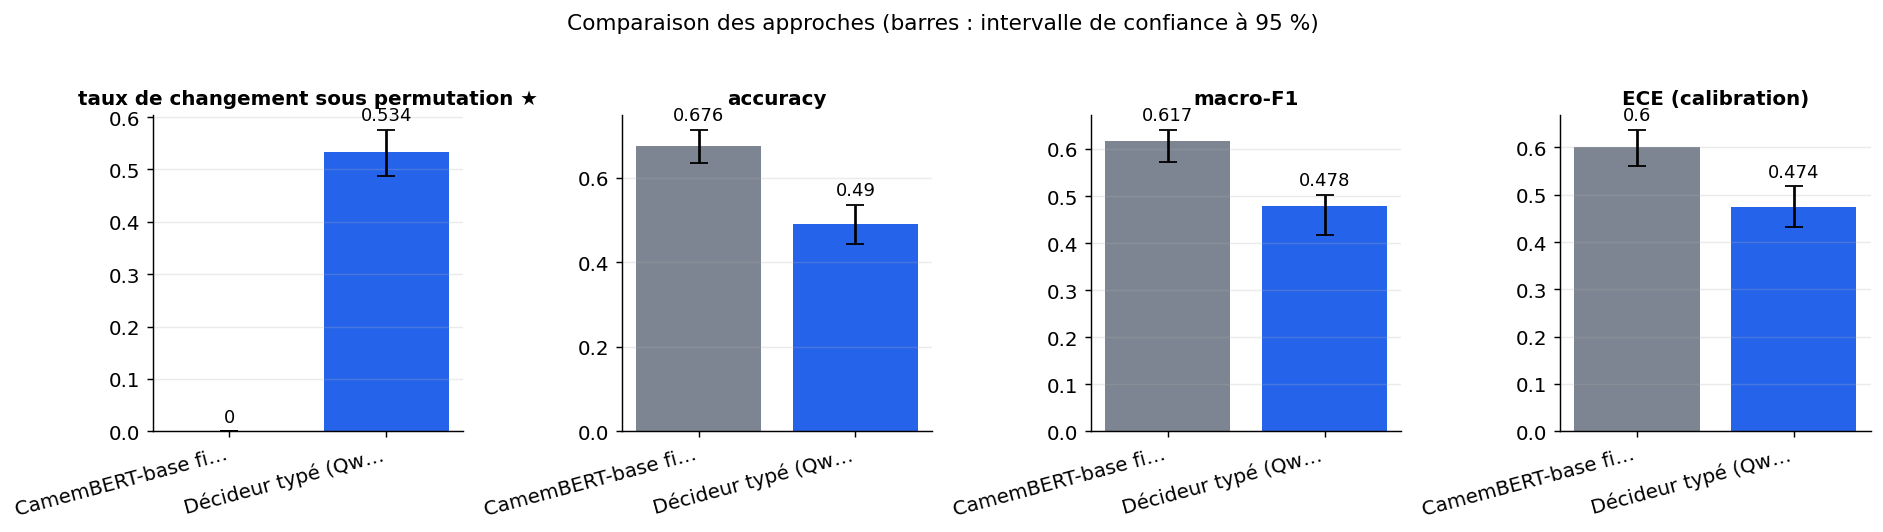

*Figure — Valeur de chaque métrique par approche (★ : métrique principale, à minimiser) ; les barres d'erreur donnent l'intervalle de confiance à 95 % sur 500 exemples de test.*

In [39]:
runtime_note = ", ".join(f"{k} = {v}" for k, v in decider_runtime.items())
results = save_results({
    "primary_metric": "permutation_flip_rate", "direction": "min", "metric_labels": METRIC_LABELS,
    "dataset": {**dataset_info, "n_examples": int(n_evaluated)},
    "approaches": [
        {"name": "CamemBERT-base fine-tuné", "role": "reference", "metrics": reference_metrics,
         "ci95": reference_ci, "latency_ms": latency_stats(reference_latencies),
         "notes": f"{EPOCHS} époques, lr {LEARNING_RATE}, lots de {BATCH_SIZE}, plafond {MAX_LENGTH} tokens, "
                  f"{len(train_df)} textes d'entraînement ; changement mesuré en relançant l'inférence sous "
                  f"chaque ordre (meilleur candidat affiché) ; sorties invalides sans objet."},
        {"name": f"Décideur typé ({decider.name})", "role": "new", "metrics": new_metrics,
         "ci95": new_ci, "latency_ms": latency_stats(decider_latencies),
         "notes": f"Top-{N_CANDIDATES} de CamemBERT comme options ; présentations {PRESENTATIONS} ; "
                  f"{n_evaluated} exemples évalués ; contrôle positif {control_accuracy:.2f} ; "
                  f"McNemar p = {mcnemar_p:.3g} ; {runtime_note}."},
    ],
})
display(results_table(results))
plot_comparison(results, metrics=["permutation_flip_rate", "accuracy", "macro_f1", "expected_calibration_error"])

## 6. Analyse des résultats

### Présentation par présentation

Pour chaque présentation : l'accuracy des deux approches, la part des exemples dont le choix du décideur **diffère de celui de `rank`**, la probabilité moyenne du choix et la part de sorties invalides. Si une présentation sans rapport avec le contenu, comme la note neutre, déplace l'accuracy ou les choix, c'est un signe de **sensibilité à la présentation**.

In [40]:
presentation_rows = []
for presentation in PRESENTATIONS:
    predicted = choices[presentation].fillna(INVALID).to_numpy()
    confidence = pd.to_numeric(confidences[presentation], errors="coerce")
    presentation_rows.append({
        "présentation": presentation, "accuracy décideur": presentation_accuracy[presentation],
        "accuracy CamemBERT": reference_presentation_accuracy[presentation],
        "choix du décideur différent de rank": float(np.mean(predicted != new_pred)),
        "probabilité moyenne du choix": float(confidence.mean()) if confidence.notna().any() else None,
        "sorties invalides": float(choices[presentation].isna().mean())})
display(pd.DataFrame(presentation_rows).round(3))

,présentation,accuracy décideur,accuracy CamemBERT,choix du décideur différent de rank,probabilité moyenne du choix,sorties invalides
0,rank,0.490,0.676,0.000,0.961,0.0
1,reversed,0.652,0.676,0.438,0.978,0.0
2,random,0.594,0.676,0.400,0.977,0.0
3,digits,0.436,0.676,0.296,0.882,0.0
4,neutral_note,0.528,0.544,0.156,0.965,0.0


### Figure : biais de position et hésitation

- **À gauche** : à quelle position de la liste se trouve l'option choisie. Un décideur qui suit le contenu choisit surtout le haut de la liste en ordre `rank`, puisque le bon candidat y est souvent, et la **position miroir** en ordre `reversed`. Une préférence qui ne s'inverse pas trahit un **biais de position**, comme celui que la source observe pour Jev.
- **À droite** : la part des exemples qui changent de choix selon la **marge** (probabilité du 1er choix moins celle du 2e). On s'attend à ce que les changements se concentrent là où le modèle hésite.

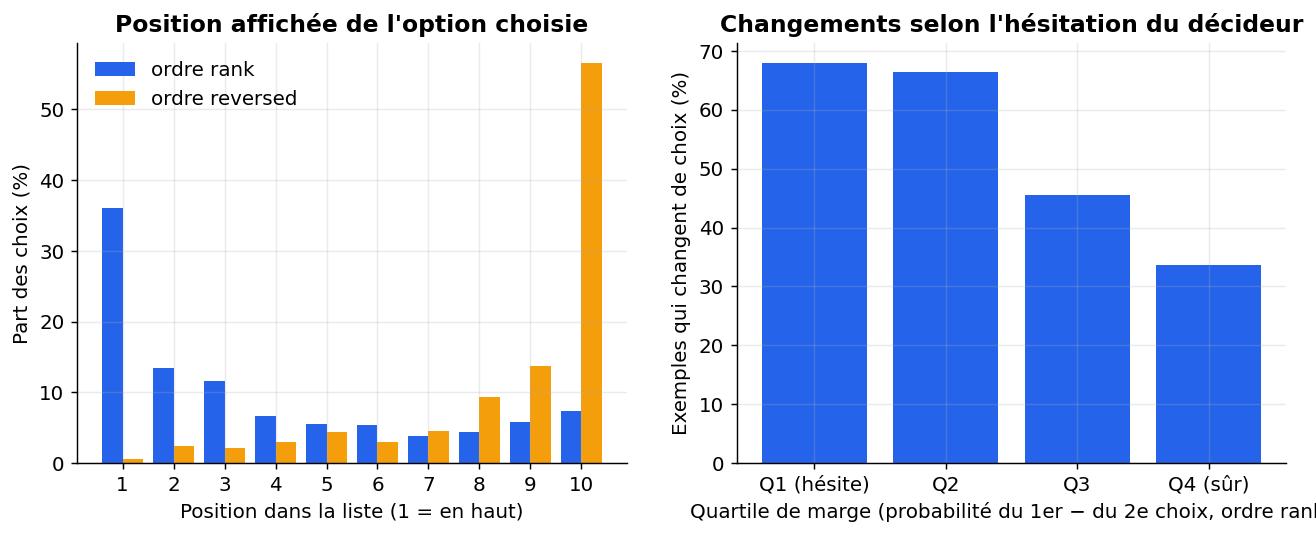

*Figure — À gauche : part des choix du décideur à chaque position affichée, en ordre rank et en ordre inversé. Deux profils en miroir signifient que le choix suit le contenu. À droite : part des exemples dont le choix change sous permutation, par quartile de marge de décision (Q1 = le décideur hésite le plus).*

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
positions = np.arange(N_CANDIDATES)
for offset, presentation, color in [(-0.2, "rank", COLORS["new"]), (0.2, "reversed", COLORS["accent"])]:
    chosen = decider_records.loc[decider_records["presentation"] == presentation, "position"].dropna().astype(int)
    share = chosen.value_counts(normalize=True).reindex(positions, fill_value=0.0)
    axes[0].bar(positions + 1 + offset, 100 * share.to_numpy(), width=0.4, color=color, label=f"ordre {presentation}")
axes[0].set(title="Position affichée de l'option choisie", xlabel="Position dans la liste (1 = en haut)",
            ylabel="Part des choix (%)", xticks=positions + 1)
axes[0].legend()
rank_records = decider_records[decider_records["presentation"] == "rank"].set_index("example")
margins = pd.to_numeric(rank_records["margin"], errors="coerce").reindex(evaluated)
if margins.notna().all():
    quartile = pd.qcut(margins.rank(method="first"), 4, labels=["Q1 (hésite)", "Q2", "Q3", "Q4 (sûr)"]).astype(str)
    by_quartile = pd.Series(100 * flips.astype(float), index=evaluated).groupby(quartile.to_numpy()).mean()
    axes[1].bar(by_quartile.index, by_quartile.to_numpy(), color=COLORS["new"])
    axes[1].set(title="Changements selon l'hésitation du décideur",
                xlabel="Quartile de marge (probabilité du 1er − du 2e choix, ordre rank)",
                ylabel="Exemples qui changent de choix (%)")
else:
    axes[1].text(0.5, 0.5, "Probabilités non fournies par le service", ha="center", va="center")
    axes[1].set_axis_off()
save_figure(fig, "position_and_flips", "À gauche : part des choix du décideur à chaque position affichée, en "
            "ordre rank et en ordre inversé. Deux profils en miroir signifient que le choix suit le contenu. "
            "À droite : part des exemples dont le choix change sous permutation, par quartile de marge de "
            "décision (Q1 = le décideur hésite le plus).")

### Figure : diagramme de fiabilité

On range les exemples par probabilité annoncée (axe horizontal), puis on mesure dans chaque tranche l'accuracy réellement observée (axe vertical). Un modèle **bien calibré** suit la diagonale : quand il annonce 80 %, il a raison 8 fois sur 10. Une courbe sous la diagonale signale un modèle **trop sûr de lui**.

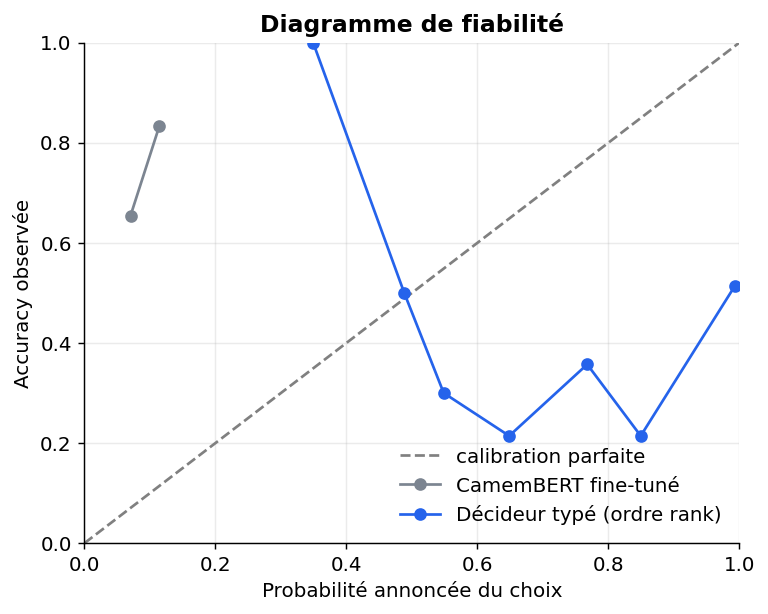

*Figure — Accuracy observée en fonction de la probabilité annoncée, par tranches de 0,1. Plus une courbe est proche de la diagonale, mieux les probabilités sont calibrées ; sous la diagonale, le modèle est trop confiant.*

In [42]:
def reliability_curve(correct: np.ndarray, confidence: np.ndarray) -> np.ndarray:
    """Par tranche de probabilité : probabilité moyenne annoncée, accuracy observée, effectif."""
    bins = np.clip(np.digitize(confidence, np.linspace(0, 1, N_BINS + 1)[1:-1]), 0, N_BINS - 1)
    return np.array([(confidence[bins == b].mean(), correct[bins == b].mean(), (bins == b).sum())
                     for b in range(N_BINS) if (bins == b).any()])


fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="calibration parfaite")
curves = {"CamemBERT fine-tuné": (correct_reference, confidence_reference, COLORS["reference"])}
if confidence_new is not None:
    curves["Décideur typé (ordre rank)"] = (correct_new, confidence_new, COLORS["new"])
for label, (correct, confidence, color) in curves.items():
    points = reliability_curve(correct.astype(float), np.asarray(confidence, dtype=float))
    ax.plot(points[:, 0], points[:, 1], marker="o", color=color, label=label)
ax.set(title="Diagramme de fiabilité", xlabel="Probabilité annoncée du choix", ylabel="Accuracy observée",
       xlim=(0, 1), ylim=(0, 1))
ax.legend()
save_figure(fig, "reliability", "Accuracy observée en fonction de la probabilité annoncée, par tranches "
            "de 0,1. Plus une courbe est proche de la diagonale, mieux les probabilités sont calibrées ; "
            "sous la diagonale, le modèle est trop confiant.")

### Appels répétés à l'identique : le niveau de bruit

La source compare chaque effet de présentation à la variation obtenue en **répétant exactement le même appel**. On fait de même sur quelques exemples, avec la présentation `rank`. Localement, une passe avant est déterministe et l'on attend 0 % ; un service peut, lui, varier. Un taux de changement sous permutation nettement au-dessus de ce bruit vient bien de la présentation.

In [43]:
N_REPEAT = sample_size(reduced=20, full=50)  # exemples réinterrogés à l'identique
first_choice = dict(zip(evaluated, new_pred))
repeat_changes = []
for i in evaluated[:N_REPEAT]:
    order, symbols = present_options(candidates[i], "rank", int(i))
    _, choice, _ = decider.decide(build_messages(test_texts[i], order, symbols, "rank"), symbols)
    repeat_changes.append((order[choice] if choice is not None else INVALID) != first_choice[i])
repeat_flip_rate = float(np.mean(repeat_changes))
display(pd.DataFrame([{"changement, appel répété à l'identique": repeat_flip_rate,
                       "changement, permutation des options": new_metrics["permutation_flip_rate"],
                       "exemples répétés": len(repeat_changes)}]).round(3))

,"changement, appel répété à l'identique","changement, permutation des options",exemples répétés
0,0.0,0.534,50


### Exemples qui basculent, ou cohérence motif / sous-motif

- **Phase publique** : quelques demandes dont le choix change selon l'ordre des options, avec la vraie intention. Elles permettent de voir si ces bascules portent sur des intentions réellement ambiguës.
- **Données internes** : aucun texte n'est affiché. On compare l'accuracy au niveau **sous-motif** à celle au niveau **motif** : une erreur qui reste dans le bon motif est moins grave pour le routage.

In [44]:
if PHASE == "public":
    flipped = np.flatnonzero(flips)[:5]
    flip_examples = pd.DataFrame({"texte": [test_texts[evaluated[k]] for k in flipped],
                                  "vraie intention": y_eval[flipped],
                                  **{f"choix ({p})": choices[p].to_numpy()[flipped] for p in ORDER_PRESENTATIONS}})
    display(flip_examples)
elif label_parent:
    true_parent = pd.Series(y_eval).map(label_parent)
    coherence_rows = []
    for name, predicted in [("CamemBERT fine-tuné", reference_pred_eval), ("Décideur typé (rank)", new_pred)]:
        predicted_parent = pd.Series(predicted).map(label_parent)
        coherence_rows.append({"approche": name, "accuracy sous-motif": accuracy_metric(y_eval, predicted),
                               "accuracy motif": float((predicted_parent == true_parent).mean())})
    display(pd.DataFrame(coherence_rows).round(3))

,texte,vraie intention,choix (rank),choix (reversed),choix (random)
0,"Je souhaite un compte pour mes enfants, commen...",age_limit,passcode_forgotten,getting_spare_card,verify_my_identity
1,Combien de temps faut-il pour que le transfert...,pending_transfer,pending_transfer,transfer_timing,pending_transfer
2,Que dois-je faire pour transférer mon salaire ...,receiving_money,receiving_money,verify_source_of_funds,receiving_money
3,J'ai accidentellement effectué une transaction...,cancel_transfer,direct_debit_payment_not_recognised,balance_not_updated_after_cheque_or_cash_deposit,balance_not_updated_after_cheque_or_cash_deposit
4,"Comment geler ma carte bancaire, suite à un re...",cash_withdrawal_not_recognised,pending_card_payment,pending_cash_withdrawal,declined_cash_withdrawal


### À retenir

- **Stabilité.** Si la borne basse de l'intervalle de confiance du taux de changement du décideur dépasse 5 %, ainsi que le taux mesuré pour CamemBERT et le bruit des appels répétés, alors le décideur typé **change d'avis à cause de la seule mise en page**. Il ne peut pas router des demandes sans garde-fou (agrégation sur plusieurs ordres, seuil de marge).
- **Précision.** L'écart d'accuracy avec CamemBERT ne se lit qu'au regard du **rappel du top-10**, qui est le plafond du décideur. Un décideur proche de ce plafond exploite bien ses options ; un décideur loin en dessous perd de l'information que CamemBERT avait déjà.
- **Calibration.** Si la courbe du décideur passe sous la diagonale, ses probabilités ne peuvent pas servir telles quelles de seuil d'abstention.
- **Garde-fous.** Si le décideur ne dépasse pas le prédicteur trivial, ou s'il échoue au contrôle positif, l'expérience est **non concluante** pour lui, quel que soit son taux de changement.
- **Portée.** Ces chiffres valent pour un proxy ouvert et, à l'échelle réduite, pour un petit modèle sur peu d'exemples. La décision se prend à l'échelle complète, puis sur les données internes.

## 7. Bilan

> **Verdict** (confiance moyenne). À l'échelle complète (500 exemples de test, GPU), le décideur typé change de choix sur 53,4 % des exemples [48,8 ; 57,6] quand l'ordre des options varie, contre 0 % pour CamemBERT. Ce résultat est net et bien au-dessus du seuil de 5 %. Il ne vient pas du bruit, puisque les appels répétés à l'identique donnent 0 %. En accuracy, le décideur atteint 0,49 en ordre du rang contre 0,676 pour CamemBERT, mais 0,652 en ordre inversé : l'écart dépend fortement de l'ordre. CamemBERT, probablement sous-entraîné (ECE de 0,60), perd lui aussi plus de dix points avec la note neutre. À l'échelle réduite, la référence était presque non entraînée et le décideur la dépassait, ce qui confirme que l'écart dépend de son niveau d'entraînement. Le protocole diffère de la source (77 classes, proxy ouvert) : on retrouve la sensibilité à la présentation, sans chiffres comparables.

*Échelle complète : 500 exemples de test de `DeepPavlov/banking77_fr` (GPU T4 (Google Colab), 6 min). La mécanique avait d'abord été validée à l'échelle réduite (150 exemples, CPU).*

| Approche | taux de changement sous permutation ★ ↓ | accuracy ↑ | macro-F1 ↑ | ECE (calibration) ↓ | rappel du top-10 (plafond) ↑ | sorties invalides ↓ | accuracy, pire présentation ↑ | accuracy, meilleure présentation | Latence médiane (ms) ↓ |
|---|---|---|---|---|---|---|---|---|---|
| CamemBERT-base fine-tuné (référence) | **0 [0 ; 0]** | **0,676 [0,636 ; 0,714]** | **0,617 [0,572 ; 0,641]** | 0,6 [0,56 ; 0,638] | 0,954 [0,934 ; 0,97] | — | **0,544** | 0,676 | 12,6 |
| Décideur typé (Qwen/Qwen3-1.7B) (nouvelle approche) | 0,534 [0,488 ; 0,576] | 0,49 [0,444 ; 0,536] | 0,478 [0,418 ; 0,503] | **0,474 [0,431 ; 0,518]** | 0,954 [0,934 ; 0,97] | 0 [0 ; 0] | 0,436 | 0,652 | 55,4 |

★ métrique principale · ↑ plus haut = meilleur · ↓ plus bas = meilleur · entre crochets : intervalle de confiance à 95 % (bootstrap) · en gras : la meilleure valeur.

**Réserves**

- CamemBERT est probablement sous-ajusté. L'écart de précision réel avec un classifieur correctement entraîné est sans doute plus grand que celui mesuré, et le rappel du top-10 est probablement sous-estimé.
- L'écart de précision n'a pas de valeur unique. Il va d'environ 19 points (ordre du rang) à environ 2 points (ordre inversé), ce qui est en soi un signe de sensibilité à la présentation. Le chiffre d'accuracy affiché est le pire cas d'ordre.
- CamemBERT n'est stable que sous permutation des options. Un texte annexe sans rapport lui coûte plus de dix points d'accuracy, donc la stabilité de la référence est moins nette que le 0 % affiché.
- Ne pas conclure que le décideur est mieux calibré que CamemBERT. Les deux ECE ne mesurent pas la même chose, et le décideur est en réalité très sur-confiant.
- Le taux de changement mesuré vaut pour ce petit modèle ouvert et ce prompt. Il confirme la sensibilité à l'ordre dans ce cas, mais ne dit rien de précis sur les services propriétaires audités dans la source.

**Limites**

- Le décideur typé est un proxy ouvert (Qwen3) ; les services propriétaires étudiés par la source ne sont pas testés.
- Les noms d'intention sont en anglais, alors que les demandes sont en français et issues d'une traduction automatique, ce qui peut pénaliser le décideur.
- Les candidats viennent du top-10 de CamemBERT : le décideur dépend de la référence, et son accuracy est bornée par ce rappel.
- Le taux de changement de CamemBERT ne mesure que le bruit numérique et l'ordre de lecture des candidats : il est attendu proche de 0, car son entrée ne contient pas les options.
- À l'échelle réduite, une référence peu entraînée et un petit décideur sur 150 exemples donnent des intervalles larges ; seule l'échelle complète permet de trancher.

**Échelle réduite : ce qui diffère de l'échelle complète**

- À l'échelle réduite : Qwen3-0.6B remplace Qwen3-1.7B, et le calcul se fait en float32 sur CPU. CamemBERT est entraîné sur 800 textes (720 en entraînement, 80 en validation) pendant 2 époques, avec un taux de 1e-4 et des lots de 16. Le test compte 150 exemples, et seules les trois présentations d'ordre sont évaluées : digits et neutral_note ne sont exercées que sur un exemple. Le contrôle positif et les appels répétés portent sur 20 exemples.

**Améliorations possibles**

- Les écarts de macro-F1 sont bruités et ne doivent pas être sur-interprétés. L'accuracy du classifieur pourrait varier d'une graine d'entraînement à l'autre.
- La latence du décideur (55 ms) s'ajoute à celle de CamemBERT (13 ms) puisqu'il dépend de ses candidats : le pipeline est plus lent que le chiffre affiché.

**Et ensuite ?** Rejouer le même protocole sur vos données : `PHASE = "private"`, `SCALE = "full"`, après avoir préparé le jeu et la configuration décrits dans le README (section « Sur vos données »).